# **Logistic** **Regressrion**

In [11]:
#Task 6
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Load the dataset
df = pd.read_csv('/content/alzheimers_disease_data.csv')

# 2. Inspect the dataset
print("--- Dataset Information ---")
print(df.info())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n--- Descriptive Statistics ---")
print(df.describe(include='all'))

print("\n--- Distribution of Diagnosis ---")
if 'Diagnosis' in df.columns:
    print(df['Diagnosis'].value_counts(normalize=True))
else:
    print("Diagnosis column not found!")

# 3. Remove PatientID and DoctorInCharge if they exist
columns_to_remove = ['PatientID', 'DoctorInCharge']
existing_cols_to_remove = [col for col in columns_to_remove if col in df.columns]
df_cleaned = df.drop(columns=existing_cols_to_remove)
print(f"\nRemoved columns: {existing_cols_to_remove}")

# 4. Split the data 80:20 with stratification and random_state=42
X = df_cleaned.drop(columns=['Diagnosis']) if 'Diagnosis' in df_cleaned.columns else df_cleaned
y = df_cleaned['Diagnosis'] if 'Diagnosis' in df_cleaned.columns else None

if y is not None:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"\nData split successful:")
    print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

    # 5. Fit preprocessing only on the training data
    # Identify numerical and categorical features
    num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
        ]
    )

    # Fit only on training data
    preprocessor.fit(X_train)

    # Transform both train and test
    X_train_preprocessed = preprocessor.transform(X_train)
    X_test_preprocessed = preprocessor.transform(X_test)

    print("Preprocessing fitted on training data and applied to both train and test splits.")
else:
    print("Could not split or preprocess because target 'Diagnosis' was not found.")

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes            

In [12]:
#Task7
from sklearn.linear_model import LogisticRegression

# 1. Unregularized Logistic Regression
# Note: 'C' is ignored when penalty=None, but max_iter is applied.
model_unregularized = LogisticRegression(
    penalty=None,
    max_iter=1000,
    solver='saga'
)
model_unregularized.fit(X_train, y_train)

# 2. L2 Regularized Logistic Regression (Ridge)
model_l2 = LogisticRegression(
    penalty='l2',
    C=1.0,
    max_iter=1000,
    solver='saga'
)
model_l2.fit(X_train, y_train)

# 3. L1 Regularized Logistic Regression (Lasso)
model_l1 = LogisticRegression(
    penalty='l1',
    C=1.0,
    max_iter=1000,
    solver='saga'
)
model_l1.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(max_iter=1000, penalty='l1', solver='saga')

In [13]:
#Task8
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# 1. Train the models on preprocessed data
log_reg_none = LogisticRegression(penalty=None, max_iter=1000, random_state=42)
log_reg_none.fit(X_train_preprocessed, y_train)

log_reg_l2 = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42)
log_reg_l2.fit(X_train_preprocessed, y_train)

log_reg_l1 = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=1000, random_state=42)
log_reg_l1.fit(X_train_preprocessed, y_train)

# 2. Define a function to compute performance metrics
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    y_pred = model.predict(X_te)
    y_prob_tr = model.predict_proba(X_tr)[:, 1]
    y_prob_te = model.predict_proba(X_te)[:, 1]

    return {
        'Model': name,
        'Test Accuracy': accuracy_score(y_te, y_pred),
        'Test Precision': precision_score(y_te, y_pred),
        'Test Recall': recall_score(y_te, y_pred),
        'Test F1-Score': f1_score(y_te, y_pred),
        'Train ROC-AUC': roc_auc_score(y_tr, y_prob_tr),
        'Test ROC-AUC': roc_auc_score(y_te, y_prob_te)
    }

# 3. Create comparison DataFrame
metrics = [
    evaluate_model(log_reg_none, X_train_preprocessed, y_train, X_test_preprocessed, y_test, 'Unregularized'),
    evaluate_model(log_reg_l2, X_train_preprocessed, y_train, X_test_preprocessed, y_test, 'L2 (C=1.0)'),
    evaluate_model(log_reg_l1, X_train_preprocessed, y_train, X_test_preprocessed, y_test, 'L1 (C=1.0)')
]

comparison_df = pd.DataFrame(metrics)
print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

        Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score  Train ROC-AUC  Test ROC-AUC
Unregularized         0.8163          0.7417       0.7368         0.7393         0.9119        0.8854
   L2 (C=1.0)         0.8163          0.7417       0.7368         0.7393         0.9119        0.8854
   L1 (C=1.0)         0.8186          0.7434       0.7434         0.7434         0.9121        0.8858


In [14]:
#Task9
import numpy as np
import pandas as pd

# Get the feature names from the preprocessor
feature_names = num_features  # Since cat_features is empty, preprocessed features align with num_features

# Extract coefficients from the unregularized model
coefficients = log_reg_none.coef_[0]

# Calculate odds ratios
odds_ratios = np.exp(coefficients)

# Create a DataFrame to display coefficients and odds ratios
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient (Beta)': coefficients,
    'Odds Ratio (e^Beta)': odds_ratios,
    'Absolute Coefficient': np.abs(coefficients)
})

# Sort by absolute coefficient to identify the most influential features
coef_df_sorted = coef_df.sort_values(by='Absolute Coefficient', ascending=False).drop(columns=['Absolute Coefficient'])

print("=== Model Coefficients & Odds Ratios ===")
display(coef_df_sorted.round(4))

print("\n=== Top 5 Most Influential Features ===")
top_5 = coef_df_sorted.head(5)
for idx, row in top_5.iterrows():
    direction = "increases" if row['Coefficient (Beta)'] > 0 else "decreases"
    print(f"- {row['Feature']}: Coefficient = {row['Coefficient (Beta)']:.4f}, Odds Ratio = {row['Odds Ratio (e^Beta)']:.4f} ({direction} the odds of diagnosis)")

=== Model Coefficients & Odds Ratios ===


,Feature,Coefficient (Beta),Odds Ratio (e^Beta)
23,FunctionalAssessment,-1.3390,0.2621
26,ADL,-1.2906,0.2751
24,MemoryComplaints,1.1539,3.1707
25,BehavioralProblems,0.9432,2.5681
22,MMSE,-0.8726,0.4178
19,CholesterolLDL,-0.1528,0.8583
20,CholesterolHDL,0.1522,1.1644
0,Age,-0.1378,0.8713
14,HeadInjury,-0.1174,0.8892
21,CholesterolTriglycerides,0.1072,1.1131



=== Top 5 Most Influential Features ===
- FunctionalAssessment: Coefficient = -1.3390, Odds Ratio = 0.2621 (decreases the odds of diagnosis)
- ADL: Coefficient = -1.2906, Odds Ratio = 0.2751 (decreases the odds of diagnosis)
- MemoryComplaints: Coefficient = 1.1539, Odds Ratio = 3.1707 (increases the odds of diagnosis)
- BehavioralProblems: Coefficient = 0.9432, Odds Ratio = 2.5681 (increases the odds of diagnosis)
- MMSE: Coefficient = -0.8726, Odds Ratio = 0.4178 (decreases the odds of diagnosis)


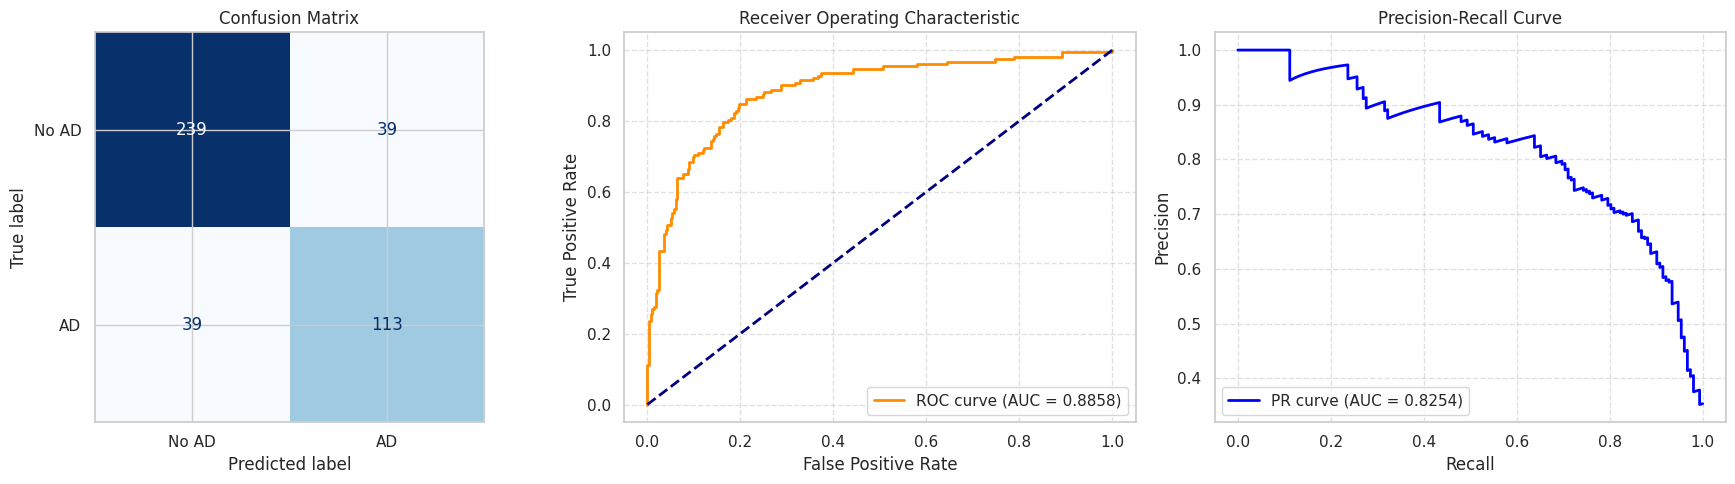

True Negatives (TN): 239
False Positives (FP): 39
False Negatives (FN): 39
True Positives (TP): 113


In [15]:
#Task10
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, auc

# Best model is L1-regularized Logistic Regression (log_reg_l1)
best_model = log_reg_l1
y_pred = best_model.predict(X_test_preprocessed)
y_prob = best_model.predict_proba(X_test_preprocessed)[:, 1]

# Calculate metrics for plotting
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No AD', 'AD'])
cmd.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

# 2. ROC Curve
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic')
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Precision-Recall Curve
axes[2].plot(recall, precision, color='blue', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend(loc="lower left")
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Extract and print exact counts of classification errors
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

### Error Analysis and Clinical Discussion
Based on the confusion matrix results from our best model (L1-regularised Logistic Regression):

* **False Positives (FP):**
  These are patients who do not have Alzheimer's but are wrongly flagged by the model as having the disease. From a clinical perspective, a false positive can cause significant emotional distress and anxiety for the patient and their family, and lead to unnecessary, costly diagnostic procedures or specialist referrals.

* **False Negatives (FN):**
  These are patients who actually have Alzheimer's but are missed by the model. Clinically, a false negative is highly dangerous as it delays critical early intervention, lifestyle modifications, and therapeutic options that could slow down cognitive decline.

* **Balancing Errors:**
  With a recall of ~74.3%, our model is quite balanced, but in a clinical screening environment, we would ideally want to decrease false negatives (increase recall) even if it leads to a slight rise in false positives, ensuring as many true positive cases are detected as early as possible.

# **Linear** **Regression**

In [2]:
#Task1
#  Step 1: Load, inspect, split, and scale the data

import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (change the file name if yours is different)
df = pd.read_csv("/content/concrete_data.csv")
print(df.head())

# 2. Inspect the data
print("Shape:", df.shape)
df.info()                                   # column names and data types
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print(df.describe())                        # basic statistics

# 3. Remove duplicate rows before splitting,
#    so the same row cannot appear in both the training and test sets
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

# 4. Define features (X) and target (y)
#    Check the exact name of the strength column in your file
target = "Concrete compressive strength "
X = df.drop(columns=[target])
y = df[target]

# 5. Split into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

# 6. Scale the features: fit on the training set only, then apply to both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

   Cement  Blast Furnace Slag  Fly Ash  Water  Superplasticizer  \
0   540.0                 0.0      0.0  162.0               2.5   
1   540.0                 0.0      0.0  162.0               2.5   
2   332.5               142.5      0.0  228.0               0.0   
3   332.5               142.5      0.0  228.0               0.0   
4   198.6               132.4      0.0  192.0               0.0   

   Coarse Aggregate  Fine Aggregate  Age (day)  Concrete compressive strength   
0            1040.0           676.0         28                       79.986111  
1            1055.0           676.0         28                       61.887366  
2             932.0           594.0        270                       40.269535  
3             932.0           594.0        365                       41.052780  
4             978.4           825.5        360                       44.296075  
Shape: (1030, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 

In [5]:
#Task2 and 3
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Define and train the models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0),
    'Lasso Regression (L1)': Lasso(alpha=0.1)
}

# Fit each model on the scaled training data
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

# We will calculate and compare MAE, RMSE, Test R2, and Train R2 for each model
results = {}

for name, model in models.items():
    # Predictions on training set
    y_train_pred = model.predict(X_train_scaled)
    # Predictions on test set
    y_test_pred = model.predict(X_test_scaled)

    # Train metrics
    train_r2 = r2_score(y_train, y_train_pred)

    # Test metrics
    test_mae = mean_absolute_error(y_test, y_test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    test_r2 = r2_score(y_test, y_test_pred)

    results[name] = {
        "Train R2": train_r2,
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    }

# Display the comparison in a structured table
results_df = pd.DataFrame(results).T
print(results_df.round(4))

print("\n--- Analysis of Overfitting and Underfitting ---")
print("1. Overfitting occurs if the model performs significantly better on the training data than on the test data (high Train R2, low Test R2).")
print("2. Underfitting occurs if the model performs poorly on both training and test data (low R2 on both).")

                       Train R2  Test MAE  Test RMSE  Test R2
Linear Regression        0.6098    8.8960    11.1922   0.5801
Ridge Regression (L2)    0.6098    8.8983    11.1942   0.5800
Lasso Regression (L1)    0.6078    8.9232    11.2302   0.5773

--- Analysis of Overfitting and Underfitting ---
1. Overfitting occurs if the model performs significantly better on the training data than on the test data (high Train R2, low Test R2).
2. Underfitting occurs if the model performs poorly on both training and test data (low R2 on both).


In [6]:
#Task 4
import pandas as pd

lr_model = models['Linear Regression']

# Create a DataFrame to display features with their standardized coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Standardized Coefficient (MPa/std dev)': lr_model.coef_
})

# Sort by absolute impact
coef_df['Abs Impact'] = coef_df['Standardized Coefficient (MPa/std dev)'].abs()
coef_df = coef_df.sort_values(by='Abs Impact', ascending=False).drop(columns=['Abs Impact'])

print(f"Linear Regression Intercept: {lr_model.intercept_:.4f} MPa\n")
display(coef_df)

Linear Regression Intercept: 35.0668 MPa



,Feature,Standardized Coefficient (MPa/std dev)
0,Cement,12.116844
1,Blast Furnace Slag,8.435504
7,Age (day),6.894768
2,Fly Ash,5.439802
3,Water,-2.835449
4,Superplasticizer,1.962320
6,Fine Aggregate,1.667185
5,Coarse Aggregate,1.194815


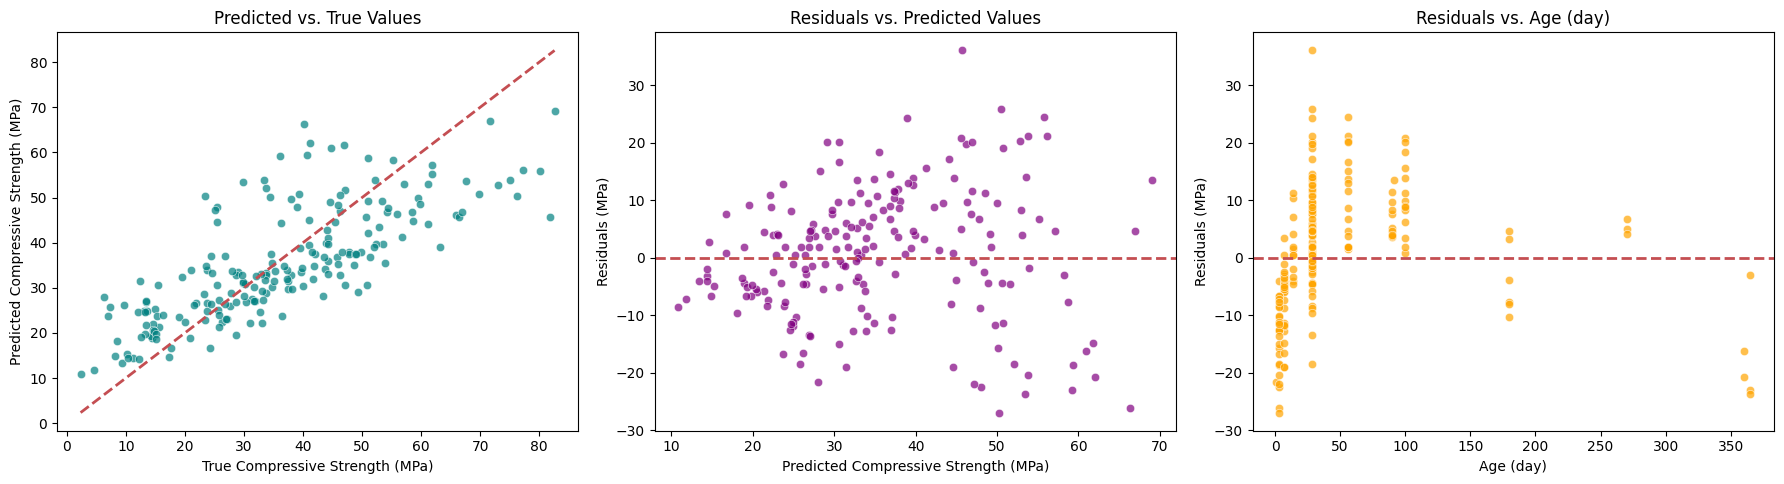

In [7]:
#Task5
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Get predictions and calculate residuals for the best model (Linear Regression)
best_model = models['Linear Regression']
y_test_pred = best_model.predict(X_test_scaled)
residuals = y_test - y_test_pred

# We need the unscaled Age column from X_test to plot against residuals
# Let's extract 'Age (day)' column from the original unscaled X_test DataFrame
age_test = X_test['Age (day)'].values

# 2. Set up the plotting grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Plot 1: Predicted vs True
sns.scatterplot(x=y_test, y=y_test_pred, ax=axes[0], alpha=0.7, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("True Compressive Strength (MPa)")
axes[0].set_ylabel("Predicted Compressive Strength (MPa)")
axes[0].set_title("Predicted vs. True Values")

# Plot 2: Residuals vs Predicted
sns.scatterplot(x=y_test_pred, y=residuals, ax=axes[1], alpha=0.7, color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel("Predicted Compressive Strength (MPa)")
axes[1].set_ylabel("Residuals (MPa)")
axes[1].set_title("Residuals vs. Predicted Values")

# Plot 3: Residuals vs Age
sns.scatterplot(x=age_test, y=residuals, ax=axes[2], alpha=0.7, color='orange')
axes[2].axhline(y=0, color='r', linestyle='--', lw=2)
axes[2].set_xlabel("Age (day)")
axes[2].set_ylabel("Residuals (MPa)")
axes[2].set_title("Residuals vs. Age (day)")

plt.tight_layout()
plt.show()